In [ ]:
import os
import time
import json
import math
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from skimage.metrics import structural_similarity as ssim_fn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset, random_split
from torchvision import datasets, transforms, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)

OUTPUT_DIR = "hasil_eksperimen"
WEIGHTS_DIR = os.path.join(OUTPUT_DIR, "weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

Device yang digunakan: cuda


In [ ]:
transform = transforms.ToTensor()

raw_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
raw_test = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
full_dataset = ConcatDataset([raw_train, raw_test])

total_len = len(full_dataset)
train_len = int(0.8 * total_len)
val_len = int(0.1 * total_len)
test_len = total_len - train_len - val_len

gen_split = torch.Generator().manual_seed(SEED)
train_set, val_set, test_set = random_split(full_dataset, [train_len, val_len, test_len], generator=gen_split)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Total data: {total_len} | Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")

100%|██████████| 26.4M/26.4M [00:00<00:00, 114MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.44MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 55.4MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.5MB/s]


Total data: 70000 | Train: 56000 | Val: 7000 | Test: 7000


In [ ]:
def hitung_metrik_rekonstruksi(reconstruct_fn, loader):
    total_mse = 0.0
    total_psnr = 0.0
    total_ssim = 0.0
    total_samples = 0

    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            x_hat = reconstruct_fn(x).clamp(0.0, 1.0)

            mse_per_img = ((x - x_hat) ** 2).view(x.size(0), -1).mean(dim=1)
            psnr_per_img = 10.0 * torch.log10(1.0 / (mse_per_img + 1e-8))

            total_mse += mse_per_img.sum().item()
            total_psnr += psnr_per_img.sum().item()

            x_np = x.cpu().numpy()
            x_hat_np = x_hat.cpu().numpy()
            for i in range(x.size(0)):
                total_ssim += ssim_fn(x_np[i, 0], x_hat_np[i, 0], data_range=1.0)

            total_samples += x.size(0)

    return total_mse / total_samples, total_psnr / total_samples, total_ssim / total_samples


def ukur_latency_batch64(sample_fn, n_warmup=2, n_runs=5):
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = sample_fn(64)
        if device.type == "cuda":
            torch.cuda.synchronize()

        times = []
        for _ in range(n_runs):
            t0 = time.perf_counter()
            _ = sample_fn(64)
            if device.type == "cuda":
                torch.cuda.synchronize()
            times.append((time.perf_counter() - t0) * 1000.0)

    return float(np.mean(times))

print("Memuat InceptionV3 untuk perhitungan FID...")
inception_model = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT, transform_input=False)
inception_model.fc = nn.Identity()
inception_model = inception_model.to(device).eval()

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def ekstrak_fitur_inception(images_tensor, batch_size=64):
    feats = []
    for i in range(0, len(images_tensor), batch_size):
        batch = images_tensor[i:i + batch_size].to(device)
        batch = batch.repeat(1, 3, 1, 1)
        batch = F.interpolate(batch, size=(299, 299), mode="bilinear", align_corners=False)
        batch = (batch - IMAGENET_MEAN) / IMAGENET_STD
        f = inception_model(batch)
        feats.append(f.cpu().numpy())
    return np.concatenate(feats, axis=0)


def hitung_fid(real_feats, fake_images_tensor):
    fake_feats = ekstrak_fitur_inception(fake_images_tensor)
    mu1, sigma1 = real_feats.mean(axis=0), np.cov(real_feats, rowvar=False)
    mu2, sigma2 = fake_feats.mean(axis=0), np.cov(fake_feats, rowvar=False)

    diff = mu1 - mu2
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff.dot(diff) + np.trace(sigma1 + sigma2 - 2.0 * covmean)
    return float(fid)

NUM_FID_SAMPLES = 1000
real_fid_list = []
for x, _ in test_loader:
    real_fid_list.append(x)
    if sum(b.size(0) for b in real_fid_list) >= NUM_FID_SAMPLES:
        break
real_fid_images = torch.cat(real_fid_list, dim=0)[:NUM_FID_SAMPLES]
real_fid_feats = ekstrak_fitur_inception(real_fid_images)
print("Fitur Inception Test Set siap:", real_fid_feats.shape)

Memuat InceptionV3 untuk perhitungan FID...
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 173MB/s]


Fitur Inception Test Set siap: (1000, 2048)


In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x))
        z_mlp = F.relu(self.fc2(h1))
        logits = self.fc3(z_mlp)
        return logits, z_mlp


def hitung_akurasi(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits, _ = model(x)
            preds = logits.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return 100.0 * correct / total

model_mlp = MLPClassifier().to(device)
opt_mlp = torch.optim.Adam(model_mlp.parameters(), lr=1e-3)
criterion_ce = nn.CrossEntropyLoss()

EPOCHS_MLP = 20
for epoch in range(1, EPOCHS_MLP + 1):
    model_mlp.train()
    total_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt_mlp.zero_grad()
        logits, _ = model_mlp(x)
        loss = criterion_ce(logits, y)
        loss.backward()
        opt_mlp.step()
        total_loss += loss.item()

    if epoch % 5 == 0 or epoch == EPOCHS_MLP:
        mlp_val_acc = hitung_akurasi(model_mlp, val_loader)
        print(f"[MLP Classifier] Epoch {epoch:02d}/{EPOCHS_MLP} | Train Loss: {total_loss/len(train_loader):.4f} | Val Acc: {mlp_val_acc:.2f}%")

mlp_test_acc = hitung_akurasi(model_mlp, test_loader)
print(f"[MLP Classifier] Final Test Accuracy: {mlp_test_acc:.2f}% (Syarat minimal: >= 88%)")

torch.save(model_mlp.state_dict(), os.path.join(WEIGHTS_DIR, "mlp_classifier.pth"))

[MLP Classifier] Epoch 05/20 | Train Loss: 0.3132 | Val Acc: 87.69%
[MLP Classifier] Epoch 10/20 | Train Loss: 0.2482 | Val Acc: 88.49%
[MLP Classifier] Epoch 15/20 | Train Loss: 0.2098 | Val Acc: 89.50%
[MLP Classifier] Epoch 20/20 | Train Loss: 0.1772 | Val Acc: 89.34%
[MLP Classifier] Final Test Accuracy: 89.47% (Syarat minimal: >= 88%)


In [ ]:
model_mlp.eval()
W1 = model_mlp.fc1.weight.data
W2 = model_mlp.fc2.weight.data
W3 = model_mlp.fc3.weight.data

sample_x, sample_y = next(iter(test_loader))
sample_x = sample_x[:8].to(device)
sample_y = sample_y[:8].to(device)

with torch.no_grad():
    y_onehot = F.one_hot(sample_y, num_classes=10).float()
    z_hat_cls = F.relu(y_onehot @ W3)
    h1_hat_cls = F.relu(z_hat_cls @ W2)
    x_hat_topdown = torch.sigmoid(h1_hat_cls @ W1).view(-1, 1, 28, 28)

    _, z_mlp_sample = model_mlp(sample_x)
    h1_hat_lat = F.relu(z_mlp_sample @ W2)
    x_hat_lat_transpose = torch.sigmoid(h1_hat_lat @ W1).view(-1, 1, 28, 28)

print("Tahap 2 & 3 selesai. Bentuk output proyeksi:", x_hat_topdown.shape, x_hat_lat_transpose.shape)

Tahap 2 & 3 selesai. Bentuk output proyeksi: torch.Size([8, 1, 28, 28]) torch.Size([8, 1, 28, 28])


In [ ]:
for param in model_mlp.parameters():
    param.requires_grad = False
model_mlp.eval()

class FrozenLatentDecoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

frozen_decoder = FrozenLatentDecoder(latent_dim=64).to(device)
opt_fdec = torch.optim.Adam(frozen_decoder.parameters(), lr=1e-3)
criterion_mse = nn.MSELoss()

EPOCHS_FDEC = 20
for epoch in range(1, EPOCHS_FDEC + 1):
    frozen_decoder.train()
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        with torch.no_grad():
            _, z_mlp = model_mlp(x)
        x_hat = frozen_decoder(z_mlp)
        loss = criterion_mse(x_hat, x)

        opt_fdec.zero_grad()
        loss.backward()
        opt_fdec.step()
        total_loss += loss.item()

    if epoch % 5 == 0 or epoch == EPOCHS_FDEC:
        frozen_decoder.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(device)
                _, z_mlp = model_mlp(x)
                val_loss += criterion_mse(frozen_decoder(z_mlp), x).item()
        print(f"[Frozen Decoder] Epoch {epoch:02d}/{EPOCHS_FDEC} | Train MSE: {total_loss/len(train_loader):.4f} | Val MSE: {val_loss/len(val_loader):.4f}")

torch.save(frozen_decoder.state_dict(), os.path.join(WEIGHTS_DIR, "frozen_latent_decoder.pth"))

frozen_decoder.eval()
fdec_mse, fdec_psnr, fdec_ssim = hitung_metrik_rekonstruksi(
    lambda x: frozen_decoder(model_mlp(x)[1]), test_loader
)
print(f"Hasil Test Frozen Latent Decoder -> MSE: {fdec_mse:.5f} | PSNR: {fdec_psnr:.2f} dB | SSIM: {fdec_ssim:.4f}")

z_mlp_all = []
with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        _, z_mlp = model_mlp(x)
        z_mlp_all.append(z_mlp)
z_mlp_all = torch.cat(z_mlp_all, dim=0)

mu_z_mlp = z_mlp_all.mean(dim=0)
sigma_z_mlp = z_mlp_all.std(dim=0)

with torch.no_grad():
    z_rand_mlp = mu_z_mlp + sigma_z_mlp * torch.randn(8, 64, device=device)
    x_mlp_prior_samples = frozen_decoder(z_rand_mlp)

print("Tahap 5 selesai. Sampel prior ruang laten MLP:", x_mlp_prior_samples.shape)

[Frozen Decoder] Epoch 05/20 | Train MSE: 0.0206 | Val MSE: 0.0205
[Frozen Decoder] Epoch 10/20 | Train MSE: 0.0186 | Val MSE: 0.0189
[Frozen Decoder] Epoch 15/20 | Train MSE: 0.0178 | Val MSE: 0.0182
[Frozen Decoder] Epoch 20/20 | Train MSE: 0.0173 | Val MSE: 0.0178
Hasil Test Frozen Latent Decoder -> MSE: 0.01790 | PSNR: 18.25 dB | SSIM: 0.6520
Tahap 5 selesai. Sampel prior ruang laten MLP: torch.Size([8, 1, 28, 28])


In [ ]:
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x.view(x.size(0), -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


model_ae = VanillaAE(latent_dim=64).to(device)
opt_ae = torch.optim.Adam(model_ae.parameters(), lr=1e-3)
criterion_mse = nn.MSELoss()

EPOCHS_AE = 20
history_ae = []
t_start = time.perf_counter()

for epoch in range(1, EPOCHS_AE + 1):
    model_ae.train()
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, _ = model_ae(x)
        loss = criterion_mse(x_hat, x)

        opt_ae.zero_grad()
        loss.backward()
        opt_ae.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    history_ae.append(avg_loss)
    if epoch % 5 == 0 or epoch == EPOCHS_AE:
        model_ae.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(device)
                val_loss += criterion_mse(model_ae(x)[0], x).item()
        print(f"[Vanilla AE] Epoch {epoch:02d}/{EPOCHS_AE} | Train Loss: {avg_loss:.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

time_per_epoch_ae = (time.perf_counter() - t_start) / EPOCHS_AE
torch.save(model_ae.state_dict(), os.path.join(WEIGHTS_DIR, "vanilla_ae.pth"))

model_ae.eval()
ae_mse, ae_psnr, ae_ssim = hitung_metrik_rekonstruksi(lambda x: model_ae(x)[0], test_loader)
ae_latency = ukur_latency_batch64(lambda b: model_ae.decode(torch.randn(b, 64, device=device)))

with torch.no_grad():
    z_ae_test = torch.cat([model_ae.encode(x.to(device)) for x, _ in test_loader], dim=0)
ae_sparsity_pct = float((z_ae_test.abs() < 1e-3).float().mean().item() * 100.0)
ae_mean_abs_z = float(z_ae_test.abs().mean().item())

print(f"[Vanilla AE] Time/Epoch: {time_per_epoch_ae:.2f}s | Latency(64): {ae_latency:.2f}ms | MSE: {ae_mse:.5f} | PSNR: {ae_psnr:.2f} dB | SSIM: {ae_ssim:.4f}")
print(f"[Vanilla AE] Sparsity (|z|<1e-3): {ae_sparsity_pct:.2f}% | Mean |z|: {ae_mean_abs_z:.4f}")

[Vanilla AE] Epoch 05/20 | Train Loss: 0.0114 | Val Loss: 0.0112
[Vanilla AE] Epoch 10/20 | Train Loss: 0.0087 | Val Loss: 0.0088
[Vanilla AE] Epoch 15/20 | Train Loss: 0.0075 | Val Loss: 0.0077
[Vanilla AE] Epoch 20/20 | Train Loss: 0.0069 | Val Loss: 0.0071
[Vanilla AE] Time/Epoch: 6.44s | Latency(64): 0.30ms | MSE: 0.00704 | PSNR: 22.62 dB | SSIM: 0.8163
[Vanilla AE] Sparsity (|z|<1e-3): 0.05% | Mean |z|: 1.2545


In [ ]:
class SparseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x.view(x.size(0), -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        h = self.encode(x)
        return self.decode(h), h


model_sae = SparseAE(latent_dim=64).to(device)
opt_sae = torch.optim.Adam(model_sae.parameters(), lr=1e-3)
LAMBDA_SPARSE = 1e-3

EPOCHS_SAE = 20
history_sae = []
t_start = time.perf_counter()

for epoch in range(1, EPOCHS_SAE + 1):
    model_sae.train()
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, h = model_sae(x)
        recon_loss = criterion_mse(x_hat, x)
        l1_penalty = torch.mean(torch.abs(h))
        loss = recon_loss + LAMBDA_SPARSE * l1_penalty

        opt_sae.zero_grad()
        loss.backward()
        opt_sae.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    history_sae.append(avg_loss)
    if epoch % 5 == 0 or epoch == EPOCHS_SAE:
        model_sae.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(device)
                x_hat, h = model_sae(x)
                val_loss += (criterion_mse(x_hat, x) + LAMBDA_SPARSE * torch.mean(torch.abs(h))).item()
        print(f"[Sparse AE] Epoch {epoch:02d}/{EPOCHS_SAE} | Train Loss: {avg_loss:.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

time_per_epoch_sae = (time.perf_counter() - t_start) / EPOCHS_SAE
torch.save(model_sae.state_dict(), os.path.join(WEIGHTS_DIR, "sparse_ae.pth"))

model_sae.eval()
sae_mse, sae_psnr, sae_ssim = hitung_metrik_rekonstruksi(lambda x: model_sae(x)[0], test_loader)
sae_latency = ukur_latency_batch64(lambda b: model_sae.decode(torch.randn(b, 64, device=device)))

with torch.no_grad():
    h_sae_test = torch.cat([model_sae.encode(x.to(device)) for x, _ in test_loader], dim=0)
sae_sparsity_pct = float((h_sae_test.abs() < 1e-3).float().mean().item() * 100.0)
sae_mean_abs_h = float(h_sae_test.abs().mean().item())

print(f"[Sparse AE] Time/Epoch: {time_per_epoch_sae:.2f}s | Latency(64): {sae_latency:.2f}ms | MSE: {sae_mse:.5f} | PSNR: {sae_psnr:.2f} dB | SSIM: {sae_ssim:.4f}")
print(f"[Sparse AE] Sparsity (|h|<1e-3): {sae_sparsity_pct:.2f}% | Mean |h|: {sae_mean_abs_h:.4f}")

[Sparse AE] Epoch 05/20 | Train Loss: 0.0130 | Val Loss: 0.0130
[Sparse AE] Epoch 10/20 | Train Loss: 0.0107 | Val Loss: 0.0108
[Sparse AE] Epoch 15/20 | Train Loss: 0.0095 | Val Loss: 0.0098
[Sparse AE] Epoch 20/20 | Train Loss: 0.0089 | Val Loss: 0.0093
[Sparse AE] Time/Epoch: 6.61s | Latency(64): 0.17ms | MSE: 0.00868 | PSNR: 21.61 dB | SSIM: 0.7811
[Sparse AE] Sparsity (|h|<1e-3): 34.35% | Mean |h|: 0.5497


In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = F.relu(self.fc1(x.view(x.size(0), -1)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def vae_loss_fn(x_hat, x, mu, logvar):
    bce = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (bce + kld) / x.size(0)


model_vae = VAE(latent_dim=64).to(device)
opt_vae = torch.optim.Adam(model_vae.parameters(), lr=1e-3)

EPOCHS_VAE = 20
history_vae = []
t_start = time.perf_counter()

for epoch in range(1, EPOCHS_VAE + 1):
    model_vae.train()
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, logvar = model_vae(x)
        loss = vae_loss_fn(x_hat, x, mu, logvar)

        opt_vae.zero_grad()
        loss.backward()
        opt_vae.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    history_vae.append(avg_loss)
    if epoch % 5 == 0 or epoch == EPOCHS_VAE:
        model_vae.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, _ in val_loader:
                x = x.to(device)
                x_hat, mu, logvar = model_vae(x)
                val_loss += vae_loss_fn(x_hat, x, mu, logvar).item()
        print(f"[VAE] Epoch {epoch:02d}/{EPOCHS_VAE} | Train Loss: {avg_loss:.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

time_per_epoch_vae = (time.perf_counter() - t_start) / EPOCHS_VAE
torch.save(model_vae.state_dict(), os.path.join(WEIGHTS_DIR, "vae.pth"))

model_vae.eval()
vae_mse, vae_psnr, vae_ssim = hitung_metrik_rekonstruksi(lambda x: model_vae.decode(model_vae.encode(x)[0]), test_loader)
vae_latency = ukur_latency_batch64(lambda b: model_vae.decode(torch.randn(b, 64, device=device)))

with torch.no_grad():
    vae_fake = model_vae.decode(torch.randn(NUM_FID_SAMPLES, 64, device=device)).cpu()
vae_fid = hitung_fid(real_fid_feats, vae_fake)
print(f"[VAE] Time/Epoch: {time_per_epoch_vae:.2f}s | Latency(64): {vae_latency:.2f}ms | MSE: {vae_mse:.5f} | PSNR: {vae_psnr:.2f} dB | SSIM: {vae_ssim:.4f} | FID: {vae_fid:.2f}")

[VAE] Epoch 05/20 | Train Loss: 249.3372 | Val Loss: 249.2658
[VAE] Epoch 10/20 | Train Loss: 244.3097 | Val Loss: 245.0251
[VAE] Epoch 15/20 | Train Loss: 242.5333 | Val Loss: 243.4546
[VAE] Epoch 20/20 | Train Loss: 241.5439 | Val Loss: 242.6068


/tmp/ipykernel_405/1609660367.py:72: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


[VAE] Time/Epoch: 6.79s | Latency(64): 0.17ms | MSE: 0.01378 | PSNR: 19.43 dB | SSIM: 0.6993 | FID: 111.93


In [ ]:
LATENT_GAN = 100

class VanillaGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x.view(x.size(0), -1))

gen_gan = VanillaGenerator(LATENT_GAN).to(device)
disc_gan = VanillaDiscriminator().to(device)
opt_g_gan = torch.optim.Adam(gen_gan.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d_gan = torch.optim.Adam(disc_gan.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion_bce = nn.BCELoss()

EPOCHS_GAN = 30
history_gan_g, history_gan_d = [], []
t_start = time.perf_counter()

for epoch in range(1, EPOCHS_GAN + 1):
    gen_gan.train()
    disc_gan.train()
    g_loss_sum, d_loss_sum = 0.0, 0.0

    for x, _ in train_loader:
        real_x = (x.to(device) * 2.0) - 1.0
        bs = real_x.size(0)
        real_lbl = torch.ones(bs, 1, device=device)
        fake_lbl = torch.zeros(bs, 1, device=device)

        z = torch.randn(bs, LATENT_GAN, device=device)
        fake_x = gen_gan(z).detach()
        d_loss = criterion_bce(disc_gan(real_x), real_lbl) + criterion_bce(disc_gan(fake_x), fake_lbl)

        opt_d_gan.zero_grad()
        d_loss.backward()
        opt_d_gan.step()

        z = torch.randn(bs, LATENT_GAN, device=device)
        gen_x = gen_gan(z)
        g_loss = criterion_bce(disc_gan(gen_x), real_lbl)

        opt_g_gan.zero_grad()
        g_loss.backward()
        opt_g_gan.step()

        g_loss_sum += g_loss.item()
        d_loss_sum += d_loss.item()

    avg_g = g_loss_sum / len(train_loader)
    avg_d = d_loss_sum / len(train_loader)
    history_gan_g.append(avg_g)
    history_gan_d.append(avg_d)
    if epoch % 5 == 0 or epoch == EPOCHS_GAN:
        print(f"[Vanilla GAN] Epoch {epoch:02d}/{EPOCHS_GAN} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f}")

time_per_epoch_gan = (time.perf_counter() - t_start) / EPOCHS_GAN
torch.save(gen_gan.state_dict(), os.path.join(WEIGHTS_DIR, "vanilla_gan_gen.pth"))
torch.save(disc_gan.state_dict(), os.path.join(WEIGHTS_DIR, "vanilla_gan_disc.pth"))

gen_gan.eval()
gan_latency = ukur_latency_batch64(lambda b: (gen_gan(torch.randn(b, LATENT_GAN, device=device)) + 1.0) / 2.0)
with torch.no_grad():
    gan_fake = ((gen_gan(torch.randn(NUM_FID_SAMPLES, LATENT_GAN, device=device)) + 1.0) / 2.0).clamp(0, 1).cpu()
gan_fid = hitung_fid(real_fid_feats, gan_fake)
print(f"[Vanilla GAN] Time/Epoch: {time_per_epoch_gan:.2f}s | Latency(64): {gan_latency:.2f}ms | FID: {gan_fid:.2f}")

[Vanilla GAN] Epoch 05/30 | D Loss: 0.8076 | G Loss: 2.0508
[Vanilla GAN] Epoch 10/30 | D Loss: 0.9042 | G Loss: 1.8153
[Vanilla GAN] Epoch 15/30 | D Loss: 0.9839 | G Loss: 1.5475
[Vanilla GAN] Epoch 20/30 | D Loss: 1.0145 | G Loss: 1.4496
[Vanilla GAN] Epoch 25/30 | D Loss: 1.0121 | G Loss: 1.4401
[Vanilla GAN] Epoch 30/30 | D Loss: 1.0298 | G Loss: 1.3693


/tmp/ipykernel_405/1609660367.py:72: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
/tmp/ipykernel_405/1609660367.py:72: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


[Vanilla GAN] Time/Epoch: 7.75s | Latency(64): 0.31ms | FID: 196.94


In [ ]:
def weights_init_dcgan(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


class DCGANGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (B, z_dim, 1, 1) -> (B, 128, 7, 7)
            nn.ConvTranspose2d(z_dim, 128, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # (B, 128, 7, 7) -> (B, 64, 14, 14)
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            # (B, 64, 14, 14) -> (B, 1, 28, 28)
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), z.size(1), 1, 1))


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # (B, 1, 28, 28) -> (B, 64, 14, 14)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # (B, 64, 14, 14) -> (B, 128, 7, 7)
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # (B, 128, 7, 7) -> (B, 1, 1, 1)
            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x).view(-1, 1)


gen_dcgan = DCGANGenerator(LATENT_GAN).to(device)
disc_dcgan = DCGANDiscriminator().to(device)
gen_dcgan.apply(weights_init_dcgan)
disc_dcgan.apply(weights_init_dcgan)

opt_g_dcgan = torch.optim.Adam(gen_dcgan.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d_dcgan = torch.optim.Adam(disc_dcgan.parameters(), lr=2e-4, betas=(0.5, 0.999))

EPOCHS_DCGAN = 30
history_dcgan_g, history_dcgan_d = [], []
t_start = time.perf_counter()

for epoch in range(1, EPOCHS_DCGAN + 1):
    gen_dcgan.train()
    disc_dcgan.train()
    g_loss_sum, d_loss_sum = 0.0, 0.0

    for x, _ in train_loader:
        real_x = (x.to(device) * 2.0) - 1.0
        bs = real_x.size(0)
        real_lbl = torch.ones(bs, 1, device=device)
        fake_lbl = torch.zeros(bs, 1, device=device)

        z = torch.randn(bs, LATENT_GAN, device=device)
        fake_x = gen_dcgan(z).detach()
        d_loss = criterion_bce(disc_dcgan(real_x), real_lbl) + criterion_bce(disc_dcgan(fake_x), fake_lbl)

        opt_d_dcgan.zero_grad()
        d_loss.backward()
        opt_d_dcgan.step()

        z = torch.randn(bs, LATENT_GAN, device=device)
        gen_x = gen_dcgan(z)
        g_loss = criterion_bce(disc_dcgan(gen_x), real_lbl)

        opt_g_dcgan.zero_grad()
        g_loss.backward()
        opt_g_dcgan.step()

        g_loss_sum += g_loss.item()
        d_loss_sum += d_loss.item()

    avg_g = g_loss_sum / len(train_loader)
    avg_d = d_loss_sum / len(train_loader)
    history_dcgan_g.append(avg_g)
    history_dcgan_d.append(avg_d)
    if epoch % 5 == 0 or epoch == EPOCHS_DCGAN:
        print(f"[DCGAN] Epoch {epoch:02d}/{EPOCHS_DCGAN} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f}")

time_per_epoch_dcgan = (time.perf_counter() - t_start) / EPOCHS_DCGAN
torch.save(gen_dcgan.state_dict(), os.path.join(WEIGHTS_DIR, "dcgan_gen.pth"))
torch.save(disc_dcgan.state_dict(), os.path.join(WEIGHTS_DIR, "dcgan_disc.pth"))

gen_dcgan.eval()
dcgan_latency = ukur_latency_batch64(lambda b: (gen_dcgan(torch.randn(b, LATENT_GAN, device=device)) + 1.0) / 2.0)
with torch.no_grad():
    dcgan_fake = ((gen_dcgan(torch.randn(NUM_FID_SAMPLES, LATENT_GAN, device=device)) + 1.0) / 2.0).clamp(0, 1).cpu()
dcgan_fid = hitung_fid(real_fid_feats, dcgan_fake)
print(f"[DCGAN] Time/Epoch: {time_per_epoch_dcgan:.2f}s | Latency(64): {dcgan_latency:.2f}ms | FID: {dcgan_fid:.2f}")

[DCGAN] Epoch 05/30 | D Loss: 0.8487 | G Loss: 1.4237
[DCGAN] Epoch 10/30 | D Loss: 0.9513 | G Loss: 1.2891
[DCGAN] Epoch 15/30 | D Loss: 1.0262 | G Loss: 1.2398
[DCGAN] Epoch 20/30 | D Loss: 1.0346 | G Loss: 1.2393
[DCGAN] Epoch 25/30 | D Loss: 0.9973 | G Loss: 1.2541
[DCGAN] Epoch 30/30 | D Loss: 1.0082 | G Loss: 1.2607


/tmp/ipykernel_405/1609660367.py:72: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


[DCGAN] Time/Epoch: 13.44s | Latency(64): 1.21ms | FID: 47.45


In [ ]:
T_STEPS = 300
betas = torch.linspace(1e-4, 0.05, T_STEPS, device=device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

class SinusoidalTimeEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        emb = math.log(10000) / (half - 1)
        emb = torch.exp(torch.arange(half, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)

class SimpleUNet(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmb(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU()
        )
        self.down1 = nn.Sequential(nn.Conv2d(1, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.SiLU())
        self.down2 = nn.Sequential(nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.GroupNorm(8, 128), nn.SiLU())
        self.down3 = nn.Sequential(nn.Conv2d(128, 128, 4, stride=2, padding=1), nn.GroupNorm(8, 128), nn.SiLU())

        self.mid = nn.Sequential(nn.Conv2d(128, 128, 3, padding=1), nn.GroupNorm(8, 128), nn.SiLU())

        self.t_proj1 = nn.Linear(time_dim, 64)
        self.t_proj2 = nn.Linear(time_dim, 128)
        self.t_proj_mid = nn.Linear(time_dim, 128)

        self.up1 = nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1)
        self.conv_up1 = nn.Sequential(nn.Conv2d(256, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.SiLU())
        self.up2 = nn.ConvTranspose2d(64, 64, 4, stride=2, padding=1)
        self.conv_up2 = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.SiLU())
        self.out = nn.Conv2d(64, 1, 1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        h1 = self.down1(x) + self.t_proj1(t_emb)[:, :, None, None]
        h2 = self.down2(h1) + self.t_proj2(t_emb)[:, :, None, None]
        h3 = self.down3(h2)

        m = self.mid(h3 + self.t_proj_mid(t_emb)[:, :, None, None])

        u1 = self.up1(m)
        u1 = self.conv_up1(torch.cat([u1, h2], dim=1))
        u2 = self.up2(u1)
        u2 = self.conv_up2(torch.cat([u2, h1], dim=1))
        return self.out(u2)


@torch.no_grad()
def ddpm_sample(model, n_samples, save_steps=None):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)
    snapshots = {}

    for t in reversed(range(T_STEPS)):
        if save_steps is not None and t in save_steps:
            snapshots[t] = ((x + 1.0) / 2.0).clamp(0, 1).cpu()

        t_batch = torch.full((n_samples,), t, device=device, dtype=torch.long)
        pred_noise = model(x, t_batch)

        alpha_t = alphas[t]
        alpha_bar_t = alphas_cumprod[t]
        beta_t = betas[t]

        mean = (1.0 / torch.sqrt(alpha_t)) * (x - ((1.0 - alpha_t) / torch.sqrt(1.0 - alpha_bar_t)) * pred_noise)
        if t > 0:
            x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
        else:
            x = mean

    x_out = ((x + 1.0) / 2.0).clamp(0, 1)
    if save_steps is not None:
        snapshots[0] = x_out.cpu()
        return x_out, snapshots
    return x_out

model_ddpm = SimpleUNet().to(device)
opt_ddpm = torch.optim.Adam(model_ddpm.parameters(), lr=3e-4)

EPOCHS_DDPM = 30
history_ddpm = []
t_start = time.perf_counter()

for epoch in range(1, EPOCHS_DDPM + 1):
    model_ddpm.train()
    total_loss = 0.0
    for x, _ in train_loader:
        x0 = (x.to(device) * 2.0) - 1.0
        bs = x0.size(0)
        t = torch.randint(0, T_STEPS, (bs,), device=device).long()
        noise = torch.randn_like(x0)

        xt = (
            sqrt_alphas_cumprod[t].view(bs, 1, 1, 1) * x0
            + sqrt_one_minus_alphas_cumprod[t].view(bs, 1, 1, 1) * noise
        )

        pred_noise = model_ddpm(xt, t)
        loss = criterion_mse(pred_noise, noise)

        opt_ddpm.zero_grad()
        loss.backward()
        opt_ddpm.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    history_ddpm.append(avg_loss)
    if epoch % 5 == 0 or epoch == EPOCHS_DDPM:
        model_ddpm.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, _ in val_loader:
                x0 = (x.to(device) * 2.0) - 1.0
                bs = x0.size(0)
                t = torch.randint(0, T_STEPS, (bs,), device=device).long()
                noise = torch.randn_like(x0)
                xt = (
                    sqrt_alphas_cumprod[t].view(bs, 1, 1, 1) * x0
                    + sqrt_one_minus_alphas_cumprod[t].view(bs, 1, 1, 1) * noise
                )
                val_loss += criterion_mse(model_ddpm(xt, t), noise).item()
        print(f"[DDPM] Epoch {epoch:02d}/{EPOCHS_DDPM} | Train MSE: {avg_loss:.4f} | Val MSE: {val_loss/len(val_loader):.4f}")

time_per_epoch_ddpm = (time.perf_counter() - t_start) / EPOCHS_DDPM
torch.save(model_ddpm.state_dict(), os.path.join(WEIGHTS_DIR, "ddpm_unet.pth"))

ddpm_latency = ukur_latency_batch64(lambda b: ddpm_sample(model_ddpm, b), n_warmup=1, n_runs=2)

ddpm_fake_list = []
for _ in range(NUM_FID_SAMPLES // 250):
    ddpm_fake_list.append(ddpm_sample(model_ddpm, 250).cpu())
ddpm_fake = torch.cat(ddpm_fake_list, dim=0)
ddpm_fid = hitung_fid(real_fid_feats, ddpm_fake)
print(f"[DDPM] Time/Epoch: {time_per_epoch_ddpm:.2f}s | Latency(64): {ddpm_latency:.2f}ms | FID: {ddpm_fid:.2f}")

[DDPM] Epoch 05/30 | Train MSE: 0.0583 | Val MSE: 0.0537
[DDPM] Epoch 10/30 | Train MSE: 0.0533 | Val MSE: 0.0526
[DDPM] Epoch 15/30 | Train MSE: 0.0516 | Val MSE: 0.0522
[DDPM] Epoch 20/30 | Train MSE: 0.0499 | Val MSE: 0.0494
[DDPM] Epoch 25/30 | Train MSE: 0.0483 | Val MSE: 0.0503
[DDPM] Epoch 30/30 | Train MSE: 0.0480 | Val MSE: 0.0505


/tmp/ipykernel_405/1609660367.py:72: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


[DDPM] Time/Epoch: 23.75s | Latency(64): 2328.53ms | FID: 60.83


In [ ]:
tabel_metrik = pd.DataFrame([
    {
        "Arsitektur Model": "Vanilla Autoencoder",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": round(time_per_epoch_ae, 2),
        "Latency (ms / batch 64)": round(ae_latency, 2),
        "Test MSE": round(ae_mse, 5),
        "Test PSNR (dB)": round(ae_psnr, 2),
        "Test SSIM": round(ae_ssim, 4),
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen"
    },
    {
        "Arsitektur Model": "Sparse Autoencoder",
        "Dim Laten": "64 (Sparse L1)",
        "Training Time / Epoch (s)": round(time_per_epoch_sae, 2),
        "Latency (ms / batch 64)": round(sae_latency, 2),
        "Test MSE": round(sae_mse, 5),
        "Test PSNR (dB)": round(sae_psnr, 2),
        "Test SSIM": round(sae_ssim, 4),
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen"
    },
    {
        "Arsitektur Model": "Variational Autoencoder (VAE)",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": round(time_per_epoch_vae, 2),
        "Latency (ms / batch 64)": round(vae_latency, 2),
        "Test MSE": round(vae_mse, 5),
        "Test PSNR (dB)": round(vae_psnr, 2),
        "Test SSIM": round(vae_ssim, 4),
        "FID Score": round(vae_fid, 2),
        "Kestabilan Training": "Stabil / Konvergen"
    },
    {
        "Arsitektur Model": "Generative Adversarial Network (Vanilla GAN)",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": round(time_per_epoch_gan, 2),
        "Latency (ms / batch 64)": round(gan_latency, 2),
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(gan_fid, 2),
        "Kestabilan Training": "Sangat Rentan Osilasi / Mode Collapse"
    },
    {
        "Arsitektur Model": "Deep Convolutional GAN (DCGAN)",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": round(time_per_epoch_dcgan, 2),
        "Latency (ms / batch 64)": round(dcgan_latency, 2),
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(dcgan_fid, 2),
        "Kestabilan Training": "Cukup Stabil (Sensitif Arsitektur)"
    },
    {
        "Arsitektur Model": "Denoising Diffusion Probabilistic Models (DDPM)",
        "Dim Laten": "28x28 (Dimensi Citra)",
        "Training Time / Epoch (s)": round(time_per_epoch_ddpm, 2),
        "Latency (ms / batch 64)": round(ddpm_latency, 2),
        "Test MSE": "N/A (Denoising Model)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": round(ddpm_fid, 2),
        "Kestabilan Training": "Sangat Stabil"
    }
])

tabel_mlp_vs_ae = pd.DataFrame([
    {
        "Model": "Frozen Latent Decoder (z_MLP, 64-d)",
        "Test MSE": round(fdec_mse, 5),
        "Test PSNR (dB)": round(fdec_psnr, 2),
        "Test SSIM": round(fdec_ssim, 4)
    },
    {
        "Model": "Vanilla Autoencoder (z_AE, 64-d)",
        "Test MSE": round(ae_mse, 5),
        "Test PSNR (dB)": round(ae_psnr, 2),
        "Test SSIM": round(ae_ssim, 4)
    }
])

tabel_metrik.to_csv(os.path.join(OUTPUT_DIR, "tabel_metrik_komparatif.csv"), index=False)
tabel_mlp_vs_ae.to_csv(os.path.join(OUTPUT_DIR, "tabel_perbandingan_mlp_vs_ae.csv"), index=False)

with open(os.path.join(OUTPUT_DIR, "training_history.json"), "w") as f:
    json.dump({
        "vanilla_ae": history_ae,
        "sparse_ae": history_sae,
        "vae": history_vae,
        "vanilla_gan_g": history_gan_g,
        "vanilla_gan_d": history_gan_d,
        "dcgan_g": history_dcgan_g,
        "dcgan_d": history_dcgan_d,
        "ddpm": history_ddpm
    }, f, indent=2)

ringkasan_tambahan = {
    "mlp_val_acc": round(mlp_val_acc, 2),
    "mlp_test_acc": round(mlp_test_acc, 2),
    "vanilla_ae_sparsity_pct": round(ae_sparsity_pct, 2),
    "vanilla_ae_mean_abs_z": round(ae_mean_abs_z, 4),
    "sparse_ae_sparsity_pct": round(sae_sparsity_pct, 2),
    "sparse_ae_mean_abs_h": round(sae_mean_abs_h, 4)
}
with open(os.path.join(OUTPUT_DIR, "ringkasan_tambahan.json"), "w") as f:
    json.dump(ringkasan_tambahan, f, indent=2)

print("=== TABEL KOMPARASI METRIK UTAMA ===")
display(tabel_metrik)
print("\n=== PERBANDINGAN FROZEN LATENT DECODER (z_MLP) VS VANILLA AE (z_AE) ===")
display(tabel_mlp_vs_ae)
print("\n=== RINGKASAN TAMBAHAN (MLP ACC & SPARSITY) ===")
print(json.dumps(ringkasan_tambahan, indent=2))

=== TABEL KOMPARASI METRIK UTAMA ===


,Arsitektur Model,Dim Laten,Training Time / Epoch (s),Latency (ms / batch 64),Test MSE,Test PSNR (dB),Test SSIM,FID Score,Kestabilan Training
0,Vanilla Autoencoder,64,6.44,0.30,0.00704,22.62,0.8163,N/A (Latent Voids),Stabil / Konvergen
1,Sparse Autoencoder,64 (Sparse L1),6.61,0.17,0.00868,21.61,0.7811,N/A (Latent Voids),Stabil / Konvergen
2,Variational Autoencoder (VAE),64,6.79,0.17,0.01378,19.43,0.6993,111.93,Stabil / Konvergen
3,Generative Adversarial Network (Vanilla GAN),100 (Prior Noise),7.75,0.31,N/A (Tanpa Encoder),N/A,N/A,196.94,Sangat Rentan Osilasi / Mode Collapse
4,Deep Convolutional GAN (DCGAN),100 (Prior Noise),13.44,1.21,N/A (Tanpa Encoder),N/A,N/A,47.45,Cukup Stabil (Sensitif Arsitektur)
5,Denoising Diffusion Probabilistic Models (DDPM),28x28 (Dimensi Citra),23.75,2328.53,N/A (Denoising Model),N/A,N/A,60.83,Sangat Stabil



=== PERBANDINGAN FROZEN LATENT DECODER (z_MLP) VS VANILLA AE (z_AE) ===


,Model,Test MSE,Test PSNR (dB),Test SSIM
0,"Frozen Latent Decoder (z_MLP, 64-d)",0.01790,18.25,0.6520
1,"Vanilla Autoencoder (z_AE, 64-d)",0.00704,22.62,0.8163



=== RINGKASAN TAMBAHAN (MLP ACC & SPARSITY) ===
{
  "mlp_val_acc": 89.34,
  "mlp_test_acc": 89.47,
  "vanilla_ae_sparsity_pct": 0.05,
  "vanilla_ae_mean_abs_z": 1.2545,
  "sparse_ae_sparsity_pct": 34.35,
  "sparse_ae_mean_abs_h": 0.5497
}


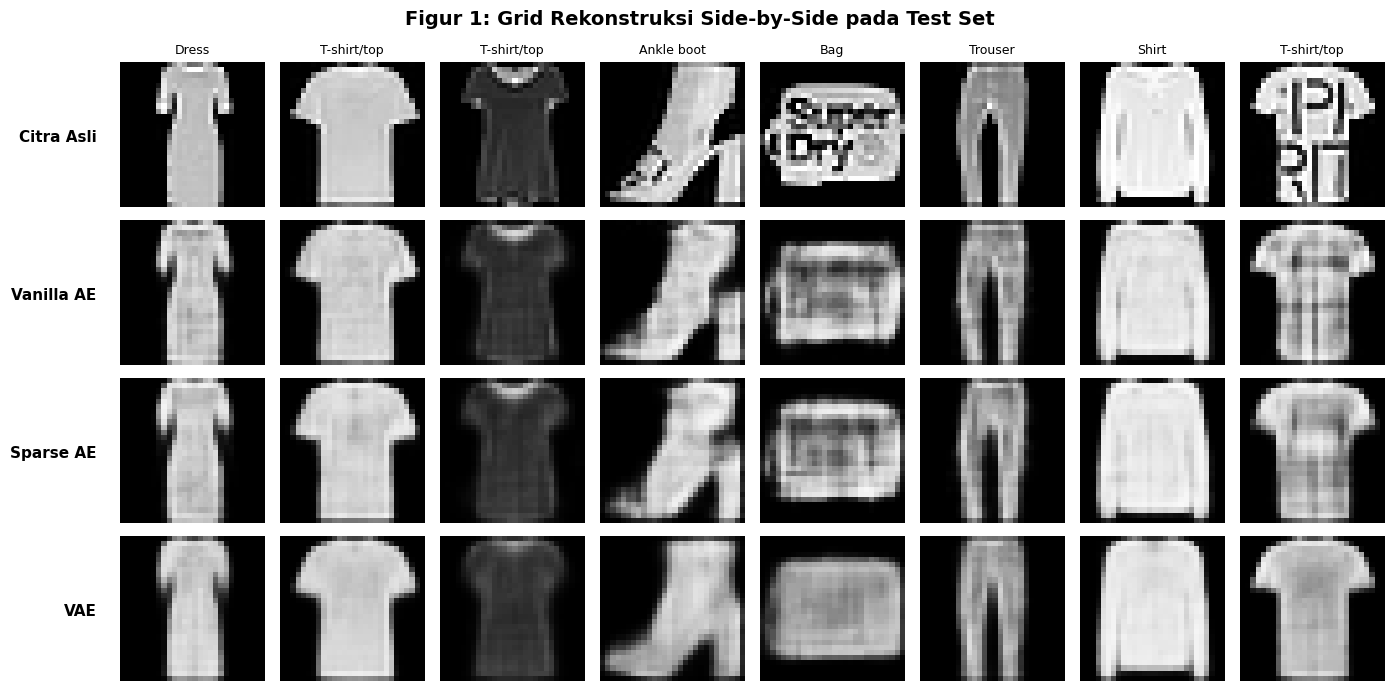

In [ ]:
model_ae.eval()
model_sae.eval()
model_vae.eval()

with torch.no_grad():
    recon_ae = model_ae(sample_x)[0].cpu()
    recon_sae = model_sae(sample_x)[0].cpu()
    recon_vae = model_vae.decode(model_vae.encode(sample_x)[0]).cpu()
    orig_cpu = sample_x.cpu()

rows_fig1 = [
    ("Citra Asli", orig_cpu),
    ("Vanilla AE", recon_ae),
    ("Sparse AE", recon_sae),
    ("VAE", recon_vae),
]

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for r, (label, imgs) in enumerate(rows_fig1):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[sample_y[c].item()], fontsize=9)
    axes[r, 0].text(-5, 14, label, va="center", ha="right", fontsize=11, fontweight="bold")

plt.suptitle("Figur 1: Grid Rekonstruksi Side-by-Side pada Test Set", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figur_1_rekonstruksi.png"), dpi=300, bbox_inches="tight")
plt.show()

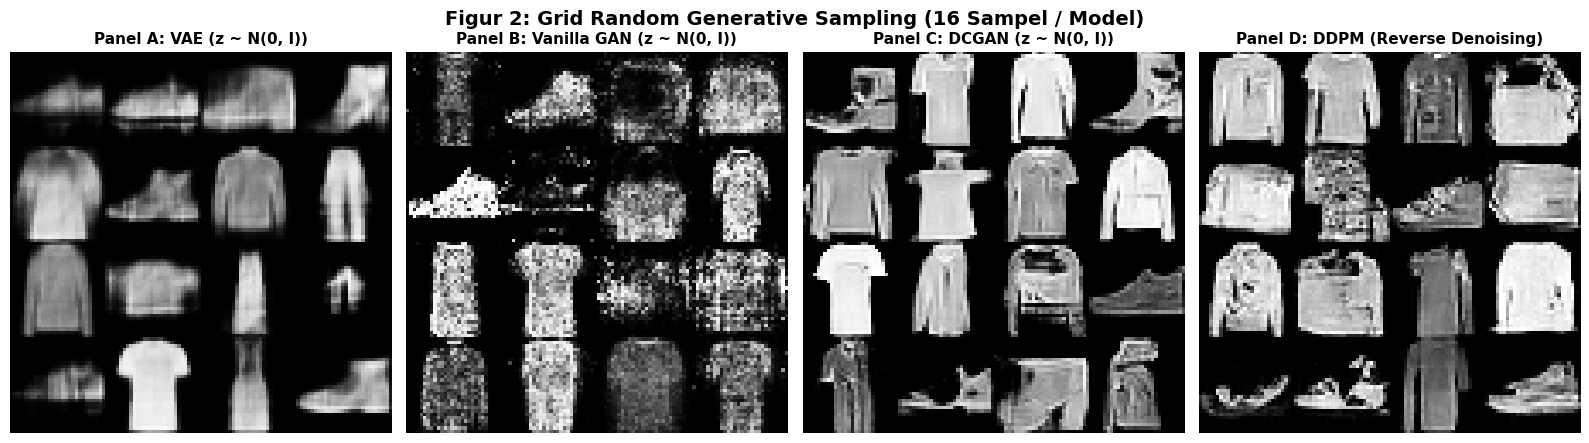

In [ ]:
with torch.no_grad():
    samp_vae = model_vae.decode(torch.randn(16, 64, device=device)).cpu()
    samp_gan = ((gen_gan(torch.randn(16, LATENT_GAN, device=device)) + 1.0) / 2.0).clamp(0, 1).cpu()
    samp_dcgan = ((gen_dcgan(torch.randn(16, LATENT_GAN, device=device)) + 1.0) / 2.0).clamp(0, 1).cpu()
    samp_ddpm = ddpm_sample(model_ddpm, 16).cpu()


def buat_grid_4x4(imgs):
    grid = np.zeros((4 * 28, 4 * 28))
    for idx in range(16):
        r, c = idx // 4, idx % 4
        grid[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = imgs[idx, 0].numpy()
    return grid


panels = [
    ("Panel A: VAE (z ~ N(0, I))", buat_grid_4x4(samp_vae)),
    ("Panel B: Vanilla GAN (z ~ N(0, I))", buat_grid_4x4(samp_gan)),
    ("Panel C: DCGAN (z ~ N(0, I))", buat_grid_4x4(samp_dcgan)),
    ("Panel D: DDPM (Reverse Denoising)", buat_grid_4x4(samp_ddpm)),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (title, grid_img) in zip(axes, panels):
    ax.imshow(grid_img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Figur 2: Grid Random Generative Sampling (16 Sampel / Model)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figur_2_random_sampling.png"), dpi=300, bbox_inches="tight")
plt.show()

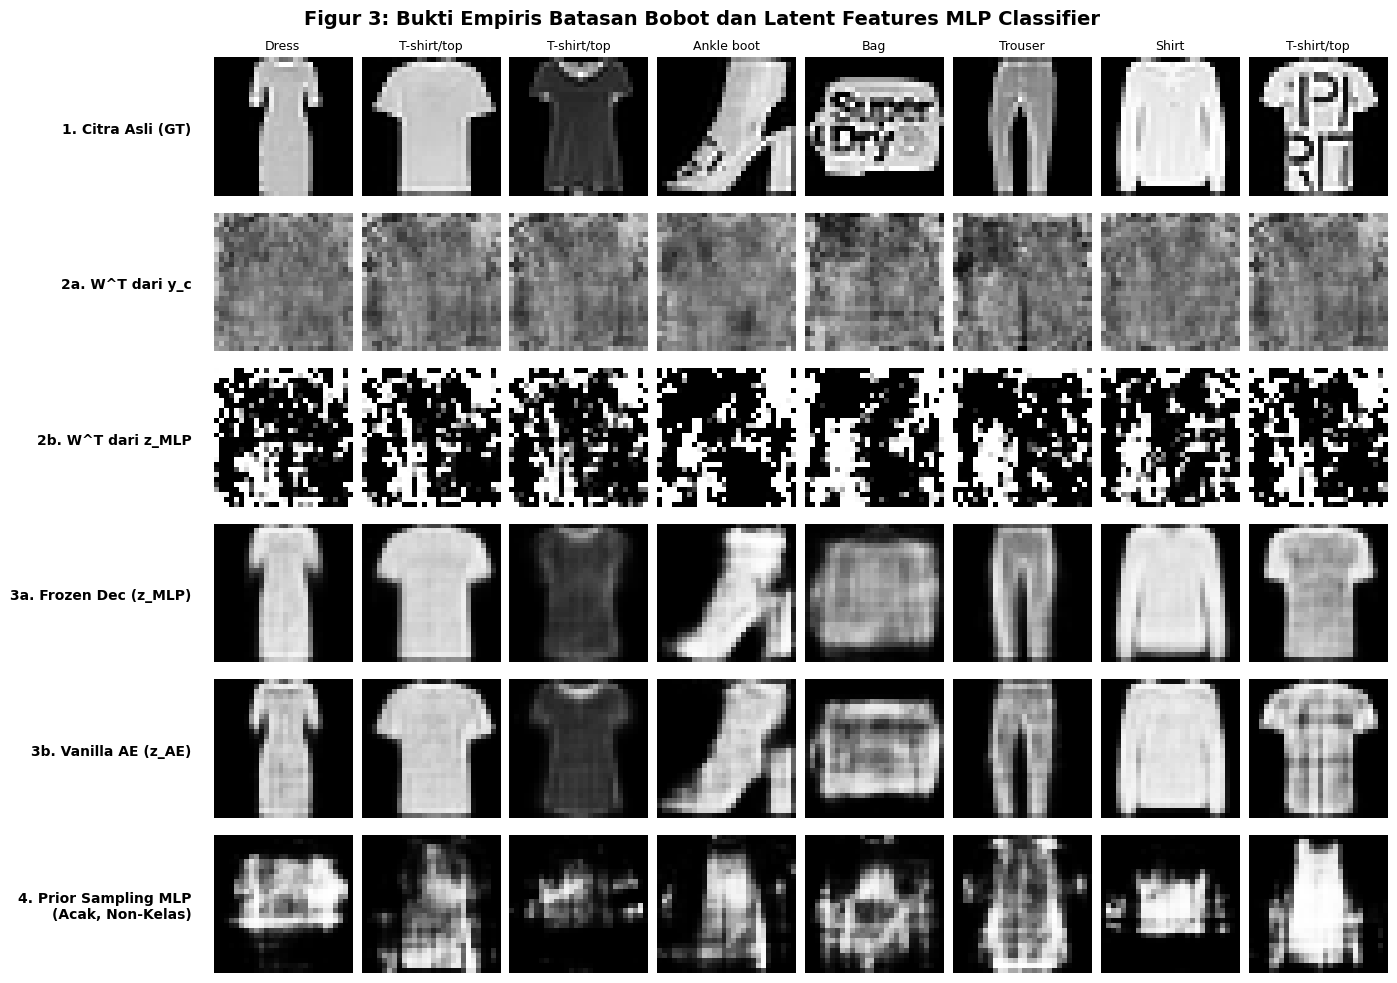

In [ ]:
with torch.no_grad():
    recon_fdec = frozen_decoder(z_mlp_sample).cpu()

rows_fig3 = [
    ("1. Citra Asli (GT)", orig_cpu),
    ("2a. W^T dari y_c", x_hat_topdown.cpu()),
    ("2b. W^T dari z_MLP", x_hat_lat_transpose.cpu()),
    ("3a. Frozen Dec (z_MLP)", recon_fdec),
    ("3b. Vanilla AE (z_AE)", recon_ae),
    ("4. Prior Sampling MLP\n(Acak, Non-Kelas)", x_mlp_prior_samples.cpu()),
]

fig, axes = plt.subplots(6, 8, figsize=(14, 10))
for r, (label, imgs) in enumerate(rows_fig3):
    for c in range(8):
        axes[r, c].imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[sample_y[c].item()], fontsize=9)
    axes[r, 0].text(-5, 14, label, va="center", ha="right", fontsize=10, fontweight="bold")

plt.suptitle("Figur 3: Bukti Empiris Batasan Bobot dan Latent Features MLP Classifier", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figur_3_batasan_mlp_classifier.png"), dpi=300, bbox_inches="tight")
plt.show()

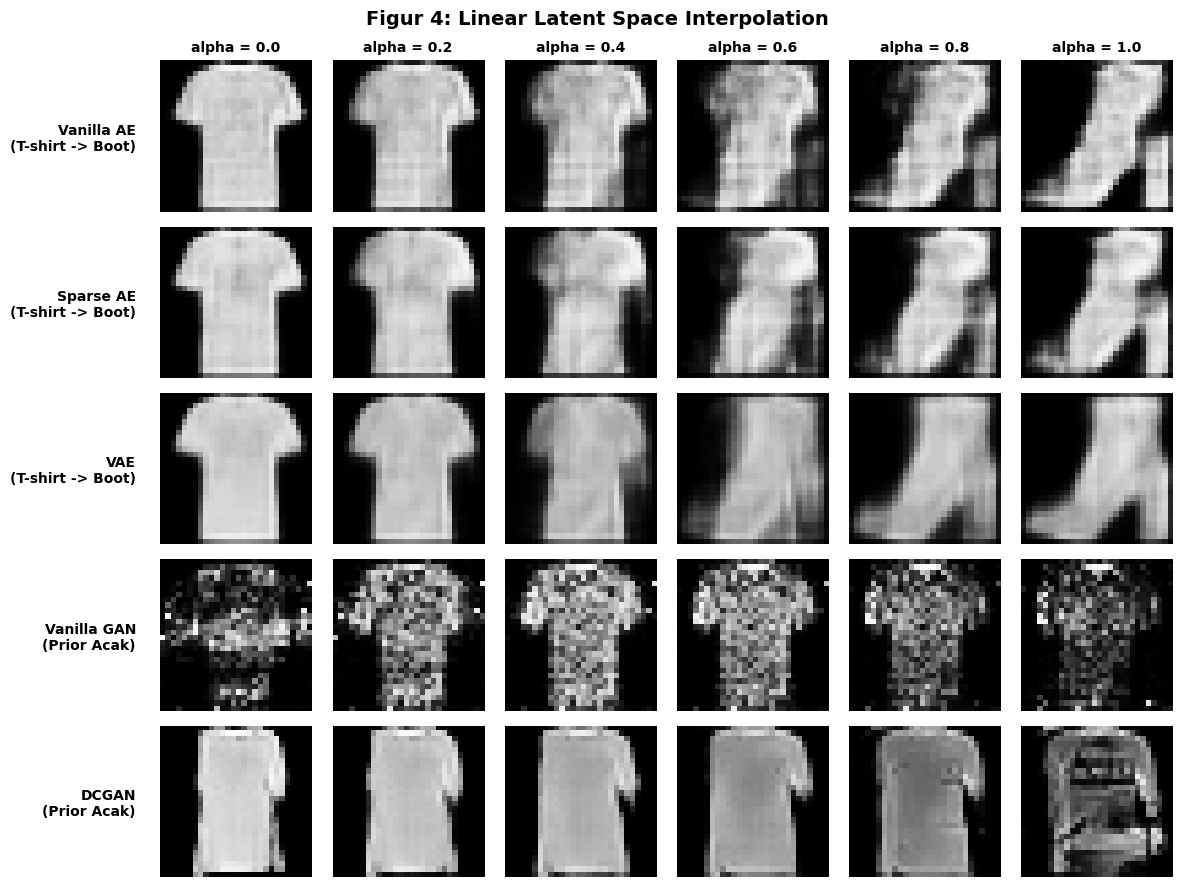

In [ ]:
img_A, img_B = None, None
for x, y in test_loader:
    for i in range(len(y)):
        if y[i].item() == 0 and img_A is None:
            img_A = x[i:i+1].to(device)
        elif y[i].item() == 9 and img_B is None:
            img_B = x[i:i+1].to(device)
    if img_A is not None and img_B is not None:
        break

alphas_interp = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

with torch.no_grad():
    zA_ae, zB_ae = model_ae.encode(img_A), model_ae.encode(img_B)
    zA_sae, zB_sae = model_sae.encode(img_A), model_sae.encode(img_B)
    zA_vae, zB_vae = model_vae.encode(img_A)[0], model_vae.encode(img_B)[0]

    zA_gan = torch.randn(1, LATENT_GAN, device=device)
    zB_gan = torch.randn(1, LATENT_GAN, device=device)

    interp_rows = [
        ("Vanilla AE\n(T-shirt -> Boot)", [model_ae.decode((1 - a) * zA_ae + a * zB_ae).cpu() for a in alphas_interp]),
        ("Sparse AE\n(T-shirt -> Boot)", [model_sae.decode((1 - a) * zA_sae + a * zB_sae).cpu() for a in alphas_interp]),
        ("VAE\n(T-shirt -> Boot)", [model_vae.decode((1 - a) * zA_vae + a * zB_vae).cpu() for a in alphas_interp]),
        ("Vanilla GAN\n(Prior Acak)", [((gen_gan((1 - a) * zA_gan + a * zB_gan) + 1.0) / 2.0).clamp(0, 1).cpu() for a in alphas_interp]),
        ("DCGAN\n(Prior Acak)", [((gen_dcgan((1 - a) * zA_gan + a * zB_gan) + 1.0) / 2.0).clamp(0, 1).cpu() for a in alphas_interp]),
    ]

fig, axes = plt.subplots(5, 6, figsize=(12, 9))
for r, (label, imgs_list) in enumerate(interp_rows):
    for c, img in enumerate(imgs_list):
        axes[r, c].imshow(img[0, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"alpha = {alphas_interp[c]:.1f}", fontsize=10, fontweight="bold")
    axes[r, 0].text(-5, 14, label, va="center", ha="right", fontsize=10, fontweight="bold")

plt.suptitle("Figur 4: Linear Latent Space Interpolation", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figur_4_interpolasi_laten.png"), dpi=300, bbox_inches="tight")
plt.show()

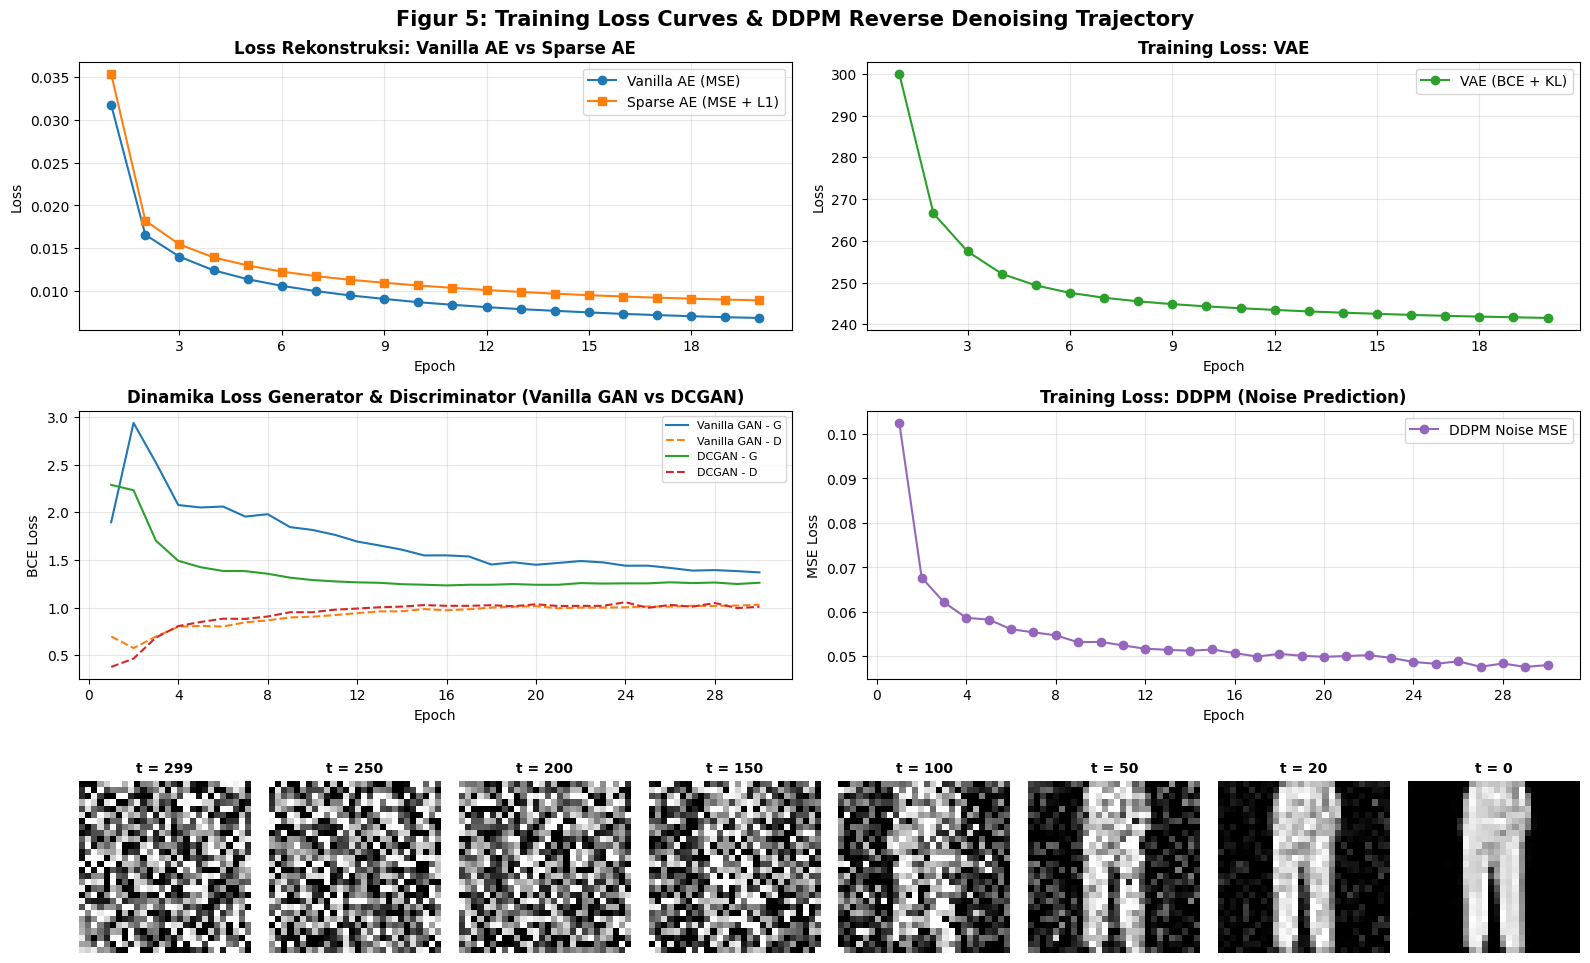

In [ ]:
steps_to_show = [299, 250, 200, 150, 100, 50, 20, 0]
_, ddpm_snaps = ddpm_sample(model_ddpm, n_samples=1, save_steps=steps_to_show)

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.8])

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(range(1, EPOCHS_AE + 1), history_ae, marker="o", label="Vanilla AE (MSE)")
ax1.plot(range(1, EPOCHS_SAE + 1), history_sae, marker="s", label="Sparse AE (MSE + L1)")
ax1.set_title("Loss Rekonstruksi: Vanilla AE vs Sparse AE", fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.legend()
ax1.grid(alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(range(1, EPOCHS_VAE + 1), history_vae, marker="o", color="tab:green", label="VAE (BCE + KL)")
ax2.set_title("Training Loss: VAE", fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax2.legend()
ax2.grid(alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(range(1, EPOCHS_GAN + 1), history_gan_g, label="Vanilla GAN - G", linestyle="-")
ax3.plot(range(1, EPOCHS_GAN + 1), history_gan_d, label="Vanilla GAN - D", linestyle="--")
ax3.plot(range(1, EPOCHS_DCGAN + 1), history_dcgan_g, label="DCGAN - G", linestyle="-")
ax3.plot(range(1, EPOCHS_DCGAN + 1), history_dcgan_d, label="DCGAN - D", linestyle="--")
ax3.set_title("Dinamika Loss Generator & Discriminator (Vanilla GAN vs DCGAN)", fontweight="bold")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("BCE Loss")
ax3.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(range(1, EPOCHS_DDPM + 1), history_ddpm, marker="o", color="tab:purple", label="DDPM Noise MSE")
ax4.set_title("Training Loss: DDPM (Noise Prediction)", fontweight="bold")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("MSE Loss")
ax4.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax4.legend()
ax4.grid(alpha=0.3)

gs_bottom = gs[2, :].subgridspec(1, len(steps_to_show))
for idx, st in enumerate(steps_to_show):
    ax_s = fig.add_subplot(gs_bottom[0, idx])
    ax_s.imshow(ddpm_snaps[st][0, 0], cmap="gray", vmin=0, vmax=1)
    ax_s.set_title(f"t = {st}", fontsize=10, fontweight="bold")
    ax_s.axis("off")

plt.suptitle("Figur 5: Training Loss Curves & DDPM Reverse Denoising Trajectory", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figur_5_loss_dan_denoising.png"), dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
zip_name = "hasil_eksperimen_generative_models"
zip_path = shutil.make_archive(zip_name, "zip", OUTPUT_DIR)
print("File zip berhasil dibuat:", zip_path)

from google.colab import files
files.download(zip_path)

File zip berhasil dibuat: /content/hasil_eksperimen_generative_models.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>